<a href="https://colab.research.google.com/github/rinlopable/PCD_Assignment03/blob/main/PCD_Assignment03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# PCD Assignment 03
## Image Segmentation and Morphological Processing

**Course:** Digital Image Processing

### Objective
Implement image segmentation and basic morphological operations from scratch, then compare the segmentation results before and after morphological processing.

### Methods
- Segmentation: Thresholding
- Morphological Operations: Erosion, Dilation, Opening, Closing


In [1]:
from google.colab import files

uploaded = files.upload()


Saving botanical_shadows.jpg to botanical_shadows.jpg


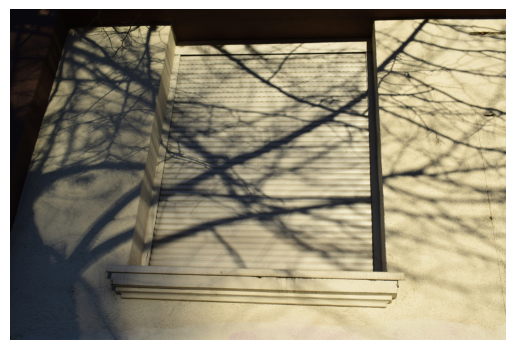

In [2]:
from PIL import Image
import matplotlib.pyplot as plt

original = Image.open("botanical_shadows.jpg")

plt.imshow(original)
plt.axis("off")
plt.show()


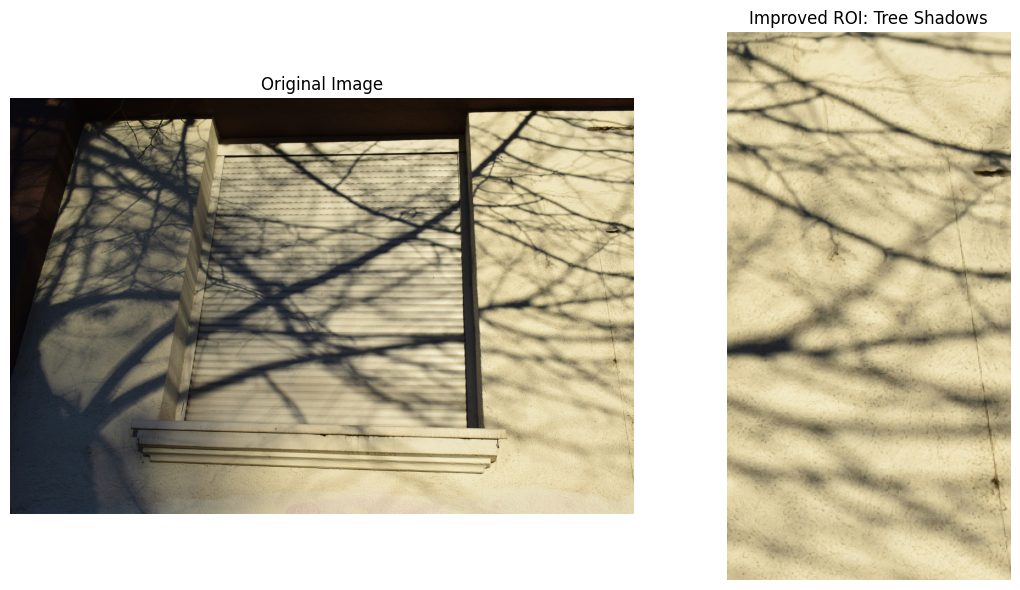

In [6]:
# STEP 3: Improved Region of Interest (ROI)

# Get original image dimensions
W, H = original.size

# Select the right wall using relative coordinates
left = int(W * 0.79)
top = int(H * 0.18)
right = int(W * 0.98)
bottom = int(H * 0.73)

# Crop the image
image = original.crop((left, top, right, bottom))

# Resize for faster processing
image.thumbnail((450, 450))

# Display original and cropped images
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image)
plt.title("Improved ROI: Tree Shadows")
plt.axis("off")

plt.tight_layout()
plt.show()



### Region of Interest (ROI)

The original image contains tree shadows, window shutters, and building structures.

To focus on shadow segmentation, a Region of Interest (ROI) was selected from the right wall of the building. This region provides a relatively bright background with darker tree shadows.

The cropped image was resized to reduce computational time for the manual implementation of segmentation and morphological operations.


In [7]:
# STEP 4: Manual RGB to Grayscale Conversion

# Get the width and height of the cropped image
width, height = image.size

# Create an empty 2D array to store grayscale values
grayscale = [[0 for x in range(width)] for y in range(height)]

# Visit every pixel in the image
for y in range(height):
    for x in range(width):

        # Get RGB values of the current pixel
        r, g, b = image.getpixel((x, y))

        # Calculate grayscale manually
        gray = round(0.299 * r + 0.587 * g + 0.114 * b)

        # Store grayscale value
        grayscale[y][x] = gray

print("Grayscale conversion completed!")
print("Image dimensions:", width, "x", height)


Grayscale conversion completed!
Image dimensions: 233 x 450


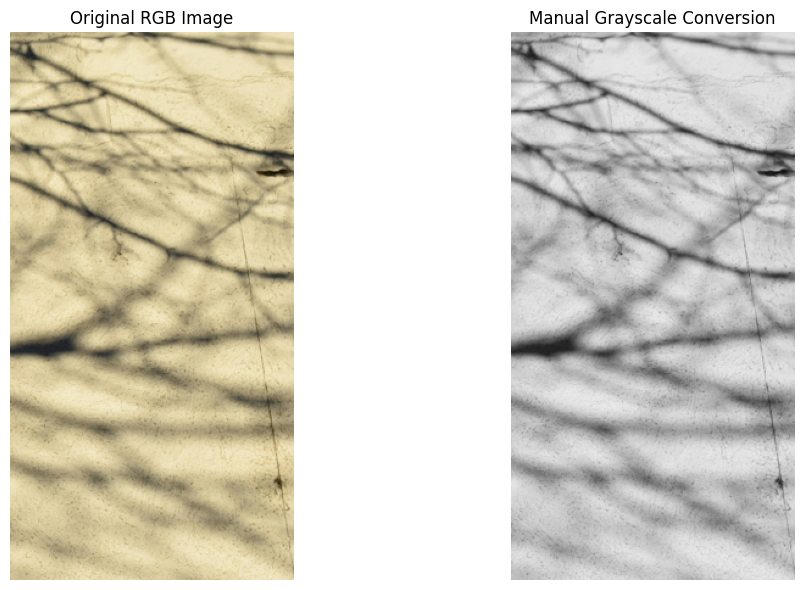

In [8]:
# Compare original RGB and grayscale images

plt.figure(figsize=(12, 6))

# Original RGB
plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original RGB Image")
plt.axis("off")

# Grayscale
plt.subplot(1, 2, 2)
plt.imshow(grayscale, cmap="gray", vmin=0, vmax=255)
plt.title("Manual Grayscale Conversion")
plt.axis("off")

plt.tight_layout()
plt.show()



### Grayscale Conversion

The cropped RGB image is converted into grayscale manually using the weighted RGB formula:

Gray = 0.299R + 0.587G + 0.114B

Each pixel is processed individually using nested loops, without relying on built-in grayscale conversion functions.

The conversion reduces the three RGB color channels into a single intensity value ranging from 0 (black) to 255 (white).

This step prepares the image for threshold-based segmentation, where darker tree shadows will be separated from the brighter wall.


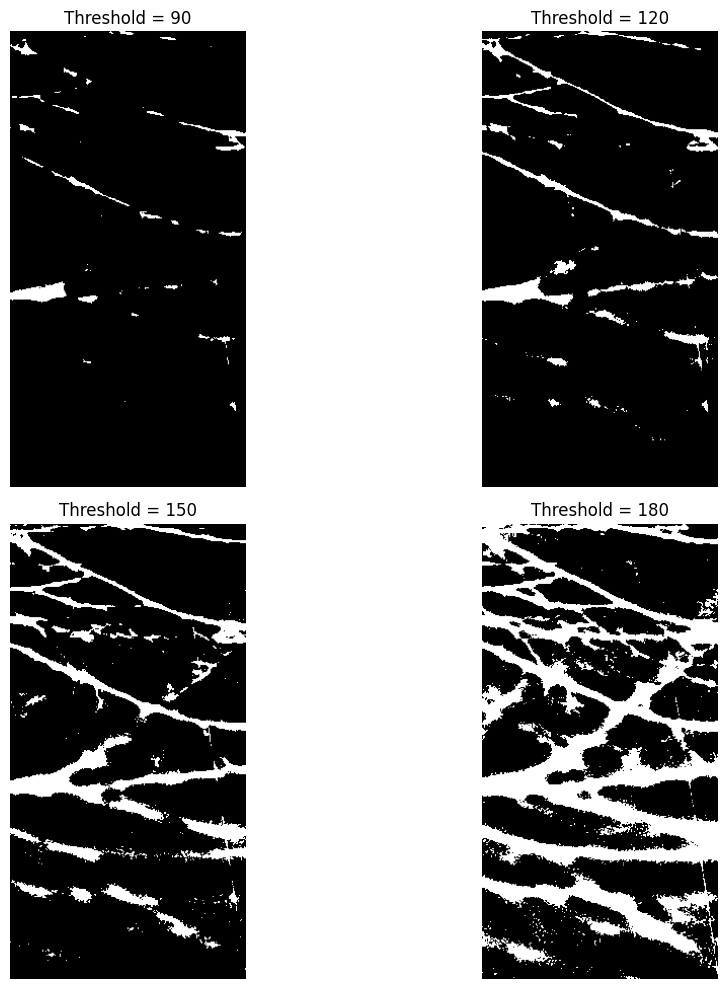

In [9]:
# STEP 5: Manual Thresholding Segmentation

# Try different threshold values
thresholds = [90, 120, 150, 180]

plt.figure(figsize=(12, 10))

for i in range(len(thresholds)):
    threshold = thresholds[i]

    # Create an empty binary image
    binary = [[0 for x in range(width)] for y in range(height)]

    # Manually classify every pixel
    for y in range(height):
        for x in range(width):
            if grayscale[y][x] < threshold:
                binary[y][x] = 255
            else:
                binary[y][x] = 0

    # Display the result
    plt.subplot(2, 2, i + 1)
    plt.imshow(binary, cmap="gray", vmin=0, vmax=255)
    plt.title(f"Threshold = {threshold}")
    plt.axis("off")

plt.tight_layout()
plt.show()


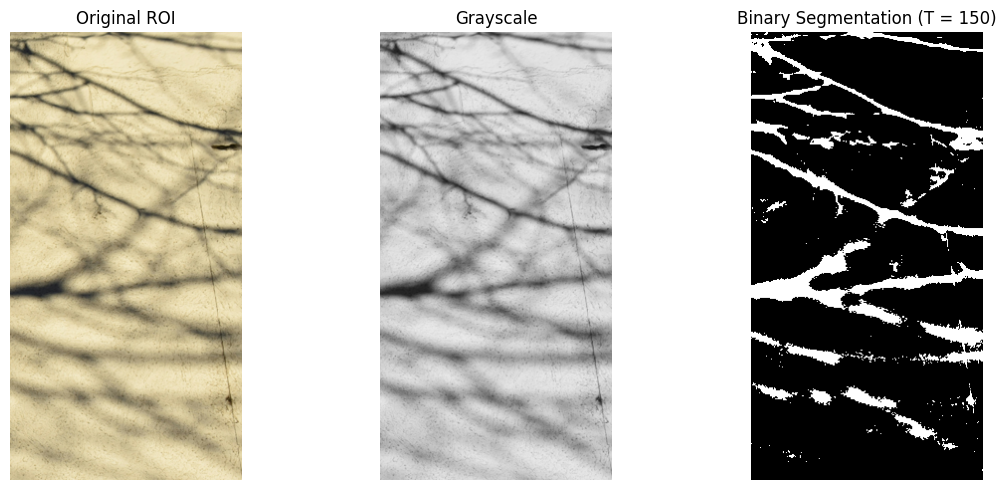

In [10]:
# STEP 5.4: Final Binary Segmentation

# Our chosen threshold
threshold = 150

# Get current image dimensions
width, height = image.size

# Create an empty binary image
binary = [[0 for x in range(width)] for y in range(height)]

# Apply manual thresholding
for y in range(height):
    for x in range(width):
        if grayscale[y][x] < threshold:
            binary[y][x] = 255  # Tree shadow
        else:
            binary[y][x] = 0    # Background wall

# Compare the images
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original ROI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(grayscale, cmap="gray", vmin=0, vmax=255)
plt.title("Grayscale")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(binary, cmap="gray", vmin=0, vmax=255)
plt.title("Binary Segmentation (T = 150)")
plt.axis("off")

plt.tight_layout()
plt.show()


### Thresholding Segmentation

Manual thresholding was implemented to separate the dark tree shadows from the brighter wall.

Several threshold values (90, 120, 150, and 180) were tested to observe how they affected the segmentation.

A threshold of 150 was selected because it provides a reasonable balance between detecting the main tree shadows and limiting unwanted background regions.

Pixels with grayscale values below 150 are classified as foreground (white), while the remaining pixels are classified as background (black).

However, some faint shadows are not detected because their brightness is similar to the background. This shows a limitation of using a single global threshold on an image with uneven lighting.


In [11]:
# STEP 6: Manual Erosion (3x3 Kernel)

# Get binary image dimensions
height = len(binary)
width = len(binary[0])

# Create an empty image to store erosion results
eroded = [[0 for x in range(width)] for y in range(height)]

# Visit every pixel in the binary image
for y in range(height):
    for x in range(width):

        # Assume the pixel should remain white
        keep_white = True

        # Check all 9 pixels in the 3x3 neighborhood
        for dy in range(-1, 2):
            for dx in range(-1, 2):

                ny = y + dy
                nx = x + dx

                # Check if neighbor is outside the image
                if ny < 0 or ny >= height or nx < 0 or nx >= width:
                    keep_white = False
                    break

                # Check if neighbor is black
                if binary[ny][nx] == 0:
                    keep_white = False
                    break

            if not keep_white:
                break

        # Store the result
        if keep_white:
            eroded[y][x] = 255
        else:
            eroded[y][x] = 0

print("Manual erosion completed!")


Manual erosion completed!


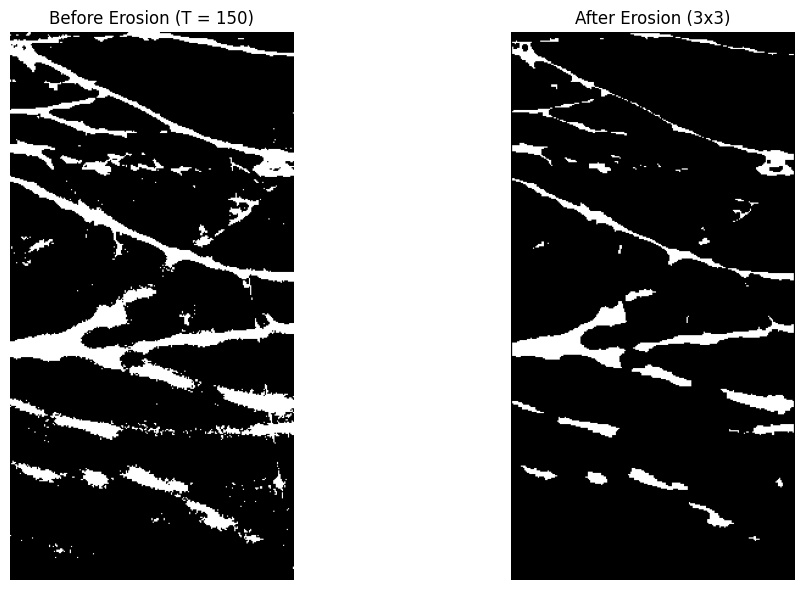

In [12]:
# STEP 6.5: Visualize Erosion Result

plt.figure(figsize=(12, 6))

# Before erosion
plt.subplot(1, 2, 1)
plt.imshow(binary, cmap="gray", vmin=0, vmax=255)
plt.title("Before Erosion (T = 150)")
plt.axis("off")

# After erosion
plt.subplot(1, 2, 2)
plt.imshow(eroded, cmap="gray", vmin=0, vmax=255)
plt.title("After Erosion (3x3)")
plt.axis("off")

plt.tight_layout()
plt.show()


In [13]:
# Count foreground pixels before erosion
before_count = 0

for row in binary:
    for pixel in row:
        if pixel == 255:
            before_count += 1

# Count foreground pixels after erosion
after_count = 0

for row in eroded:
    for pixel in row:
        if pixel == 255:
            after_count += 1

print("White pixels before erosion:", before_count)
print("White pixels after erosion:", after_count)
print("Pixels removed:", before_count - after_count)


White pixels before erosion: 14653
White pixels after erosion: 8055
Pixels removed: 6598


### Morphological Operation 1: Erosion

Erosion was implemented manually using a 3×3 structuring element.

For each pixel, the algorithm examines its 3×3 neighborhood. The center pixel remains foreground (white) only if all nine pixels are foreground. Otherwise, it becomes background (black). Pixels outside the image are treated as background.

The purpose of erosion is to shrink foreground regions and remove small details.

In this experiment, erosion is applied to the binary segmentation of tree shadows. The resulting changes in branch thickness and small details are examined by comparing the images before and after erosion.


In [14]:
# STEP 7: Manual Dilation (3x3 Kernel)

height = len(binary)
width = len(binary[0])

# Create an empty output image
dilated = [[0 for x in range(width)] for y in range(height)]

# Visit every pixel
for y in range(height):
    for x in range(width):

        # Assume the output pixel is black
        make_white = False

        # Check the 3x3 neighborhood
        for dy in range(-1, 2):
            for dx in range(-1, 2):

                ny = y + dy
                nx = x + dx

                # Only check valid positions
                if 0 <= ny < height and 0 <= nx < width:

                    # If at least one neighbor is white
                    if binary[ny][nx] == 255:
                        make_white = True
                        break

            if make_white:
                break

        # Store the result
        if make_white:
            dilated[y][x] = 255
        else:
            dilated[y][x] = 0

print("Manual dilation completed!")


Manual dilation completed!


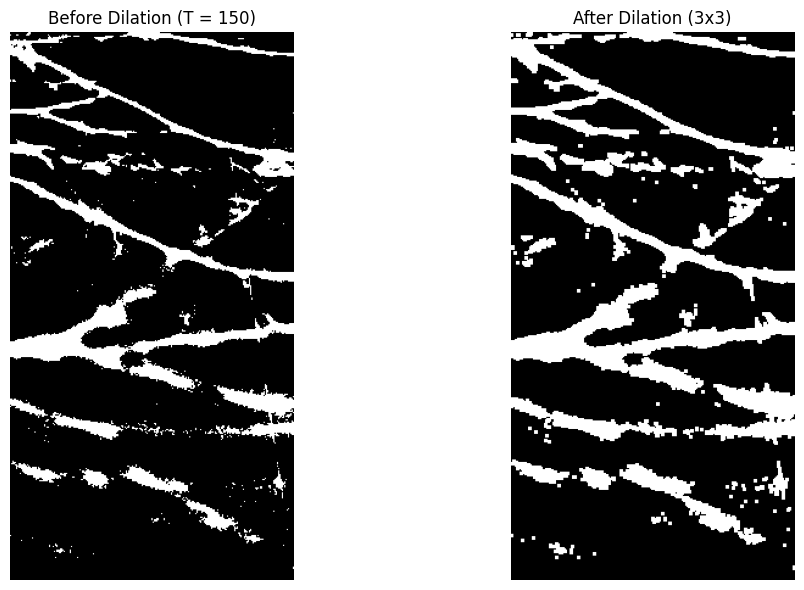

In [15]:
# STEP 7.3: Compare Before and After Dilation

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(binary, cmap="gray", vmin=0, vmax=255)
plt.title("Before Dilation (T = 150)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(dilated, cmap="gray", vmin=0, vmax=255)
plt.title("After Dilation (3x3)")
plt.axis("off")

plt.tight_layout()
plt.show()


In [16]:
# STEP 7.4: Count foreground pixels after dilation

dilation_count = 0

for row in dilated:
    for pixel in row:
        if pixel == 255:
            dilation_count += 1

print("White pixels before dilation:", before_count)
print("White pixels after dilation:", dilation_count)
print("Pixels added:", dilation_count - before_count)
print("Percentage increase:",
      round((dilation_count - before_count) / before_count * 100, 2),
      "%")


White pixels before dilation: 14653
White pixels after dilation: 22975
Pixels added: 8322
Percentage increase: 56.79 %



### Morphological Operation 2: Dilation

Dilation was implemented manually using a 3×3 structuring element.

For each pixel, the algorithm examines its 3×3 neighborhood. If at least one valid neighboring pixel is foreground (white), the output pixel becomes white. Otherwise, it remains background (black). Pixels outside the image are treated as background.

Unlike erosion, dilation expands foreground regions. In the botanical shadow image, this operation is expected to make the detected branches thicker and potentially connect nearby white regions.

The dilation result will be compared with the original binary segmentation to examine these changes.


In [17]:
# STEP 8: Manual Opening (Erosion followed by Dilation)

height = len(eroded)
width = len(eroded[0])

# Create empty output image
opened = [[0 for x in range(width)] for y in range(height)]

# Apply dilation to the ERODED image
for y in range(height):
    for x in range(width):

        make_white = False

        # Check 3x3 neighborhood
        for dy in range(-1, 2):
            for dx in range(-1, 2):

                ny = y + dy
                nx = x + dx

                # Check valid neighboring pixels
                if 0 <= ny < height and 0 <= nx < width:

                    if eroded[ny][nx] == 255:
                        make_white = True
                        break

            if make_white:
                break

        # Store opening result
        if make_white:
            opened[y][x] = 255
        else:
            opened[y][x] = 0

print("Manual opening completed!")


Manual opening completed!


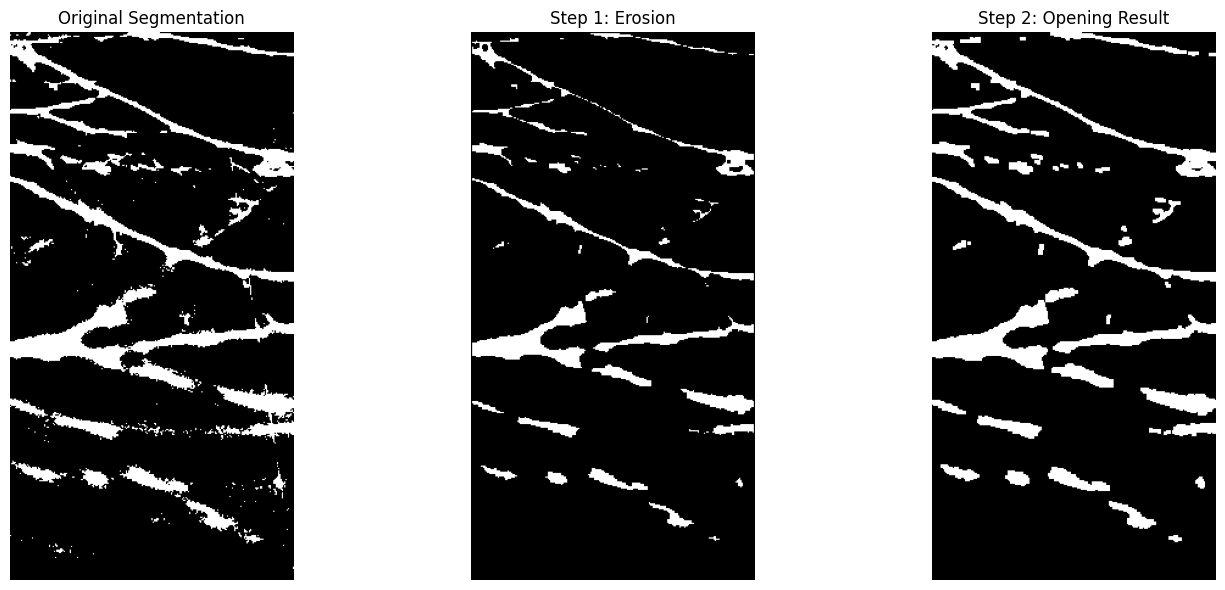

In [18]:
# STEP 8.4: Visualize Opening

plt.figure(figsize=(15, 6))

plt.subplot(1, 3, 1)
plt.imshow(binary, cmap="gray", vmin=0, vmax=255)
plt.title("Original Segmentation")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(eroded, cmap="gray", vmin=0, vmax=255)
plt.title("Step 1: Erosion")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(opened, cmap="gray", vmin=0, vmax=255)
plt.title("Step 2: Opening Result")
plt.axis("off")

plt.tight_layout()
plt.show()


In [19]:
# STEP 8.5: Count white pixels after opening

opening_count = 0

for row in opened:
    for pixel in row:
        if pixel == 255:
            opening_count += 1

print("Original white pixels:", before_count)
print("After erosion:", after_count)
print("After opening:", opening_count)

print("Pixels removed by opening:",
      before_count - opening_count)

print("Percentage removed:",
      round((before_count - opening_count) / before_count * 100, 2),
      "%")


Original white pixels: 14653
After erosion: 8055
After opening: 12879
Pixels removed by opening: 1774
Percentage removed: 12.11 %



### Morphological Operation 3: Opening

Opening is a morphological operation that combines erosion followed by dilation using the same structuring element.

In this experiment, a 3×3 structuring element was used. First, erosion was applied to remove small foreground regions and shrink the larger regions. Next, dilation was applied to the eroded image to expand the remaining foreground regions.

The purpose of opening is to remove small foreground noise while preserving larger structures.

The result is compared with the original binary segmentation and erosion result to examine how opening affects the detected tree shadows.


In [20]:

# STEP 9: Manual Closing (Dilation followed by Erosion)

height = len(dilated)
width = len(dilated[0])

# Create an empty output image
closed = [[0 for x in range(width)] for y in range(height)]

# Apply erosion to the DILATED image
for y in range(height):
    for x in range(width):

        keep_white = True

        # Check the 3x3 neighborhood
        for dy in range(-1, 2):
            for dx in range(-1, 2):

                ny = y + dy
                nx = x + dx

                # Treat pixels outside the image as black
                if ny < 0 or ny >= height or nx < 0 or nx >= width:
                    keep_white = False
                    break

                # All neighbors must be white
                if dilated[ny][nx] == 0:
                    keep_white = False
                    break

            if not keep_white:
                break

        # Store the closing result
        if keep_white:
            closed[y][x] = 255
        else:
            closed[y][x] = 0

print("Manual closing completed!")


Manual closing completed!


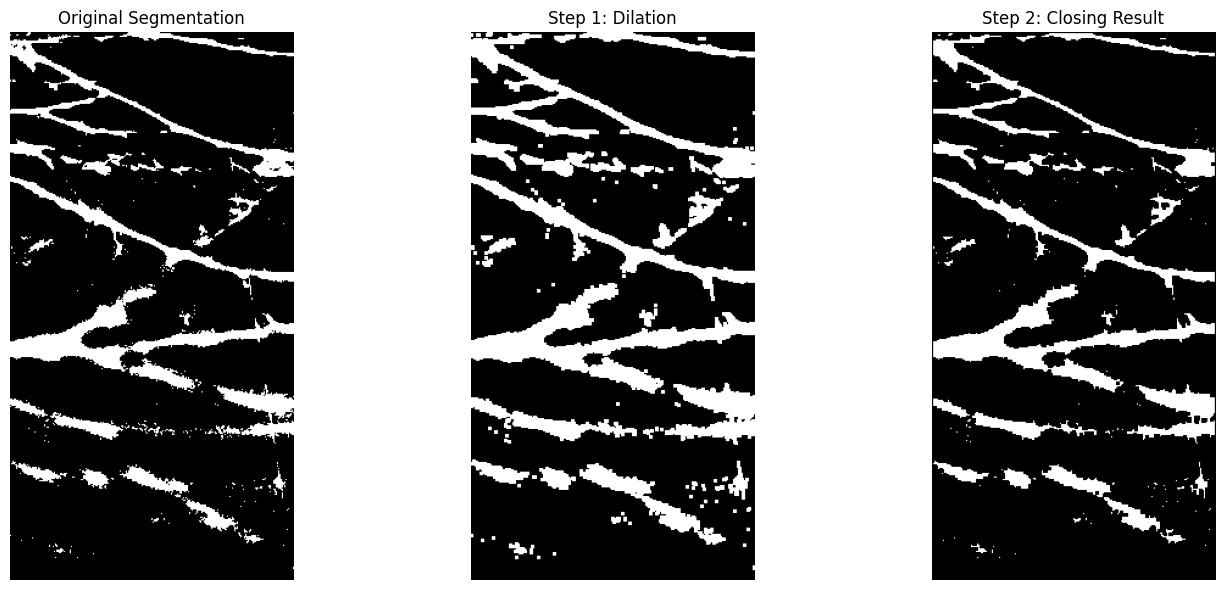

In [21]:

# STEP 9.4: Visualize Closing

plt.figure(figsize=(15, 6))

# Original binary segmentation
plt.subplot(1, 3, 1)
plt.imshow(binary, cmap="gray", vmin=0, vmax=255)
plt.title("Original Segmentation")
plt.axis("off")

# After dilation
plt.subplot(1, 3, 2)
plt.imshow(dilated, cmap="gray", vmin=0, vmax=255)
plt.title("Step 1: Dilation")
plt.axis("off")

# After closing
plt.subplot(1, 3, 3)
plt.imshow(closed, cmap="gray", vmin=0, vmax=255)
plt.title("Step 2: Closing Result")
plt.axis("off")

plt.tight_layout()
plt.show()


In [22]:

# STEP 9.5: Count white pixels after closing

closing_count = 0

for row in closed:
    for pixel in row:
        if pixel == 255:
            closing_count += 1

print("Original white pixels:", before_count)
print("After dilation:", dilation_count)
print("After closing:", closing_count)

difference = closing_count - before_count

print("Net pixel difference:", difference)

print("Percentage difference:",
      round(difference / before_count * 100, 2),
      "%")


Original white pixels: 14653
After dilation: 22975
After closing: 15534
Net pixel difference: 881
Percentage difference: 6.01 %



### Morphological Operation 4: Closing

Closing combines dilation followed by erosion using the same structuring element.

In this experiment, a 3×3 structuring element was used. First, dilation expanded the white foreground regions. Then, erosion was applied to the dilated image to reduce the expanded boundaries.

Closing is commonly used to fill small background holes and connect nearby foreground regions.

For the tree shadow segmentation, the operation is used to examine whether small gaps between detected shadow regions can be reduced.

The result is compared with the original segmentation and dilation result to evaluate changes in the structure of the detected shadows.


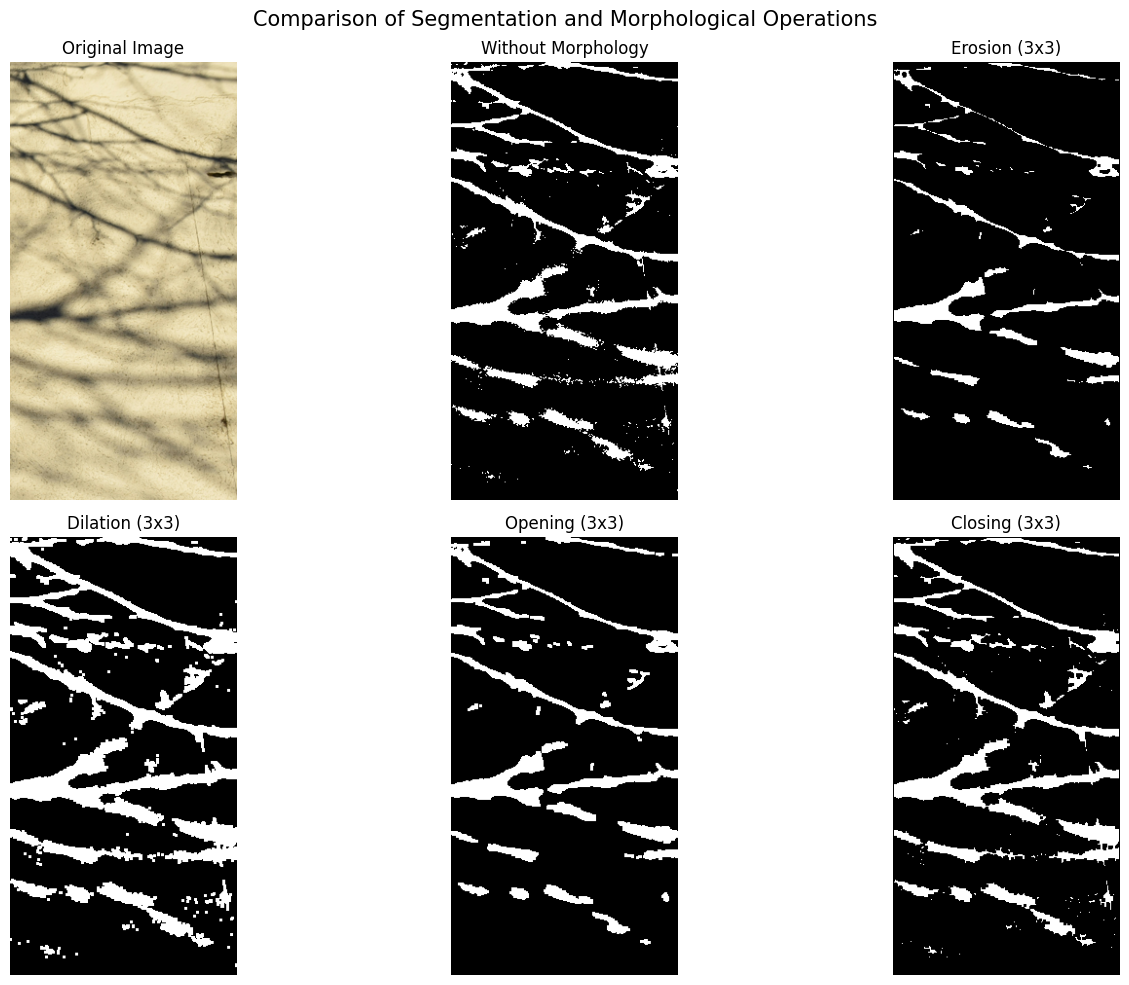

In [23]:

# STEP 10: Comparison of Segmentation and Morphology

plt.figure(figsize=(15, 10))

# Original cropped image
plt.subplot(2, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

# Results from our manual algorithms
results = [
    ("Without Morphology", binary),
    ("Erosion (3x3)", eroded),
    ("Dilation (3x3)", dilated),
    ("Opening (3x3)", opened),
    ("Closing (3x3)", closed)
]

for i in range(len(results)):
    title, result = results[i]

    plt.subplot(2, 3, i + 2)
    plt.imshow(result, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")

plt.suptitle(
    "Comparison of Segmentation and Morphological Operations",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [24]:

# STEP 10.3: Quantitative Comparison

methods = [
    ("Original", binary),
    ("Erosion", eroded),
    ("Dilation", dilated),
    ("Opening", opened),
    ("Closing", closed)
]

# Count original foreground pixels
original_count = 0

for row in binary:
    for pixel in row:
        if pixel == 255:
            original_count += 1

print(f"{'Method':<15} {'White Pixels':<15} {'Change (%)':<12}")
print("-" * 45)

for name, result in methods:

    count = 0

    for row in result:
        for pixel in row:
            if pixel == 255:
                count += 1

    change = ((count - original_count) /
              original_count) * 100

    print(f"{name:<15} {count:<15} {change:+.2f}%")


Method          White Pixels    Change (%)  
---------------------------------------------
Original        14653           +0.00%
Erosion         8055            -45.03%
Dilation        22975           +56.79%
Opening         12879           -12.11%
Closing         15534           +6.01%



## Results and Discussion

### Comparison of Segmentation With and Without Morphological Processing

The original binary segmentation was obtained using manual thresholding with a threshold value of 150. Darker pixels were classified as foreground (tree shadows), while brighter pixels were classified as background.

Four morphological operations were implemented manually using a 3×3 structuring element: erosion, dilation, opening, and closing.

### Observations

**1. Erosion**

Erosion reduced the foreground pixels from 14,653 to 8,055, a decrease of 45.03%. The white regions became thinner, and several small details disappeared. Although this removed some unwanted foreground regions, some genuine shadow details were also lost.

**2. Dilation**

Dilation increased the foreground pixels to 22,975, an increase of 56.79%. The detected shadow regions became thicker, and some nearby regions were connected. However, unwanted white regions also expanded.

**3. Opening**

Opening reduced the foreground pixels to 12,879, a decrease of 12.11%. Many small white regions disappeared while larger foreground structures were partially restored after dilation. However, some thin shadow details were lost.

**4. Closing**

Closing increased the foreground pixels to 15,534, an increase of 6.01%. Some small gaps within the detected shadow regions were reduced, while most larger structures retained approximately their original thickness.

### Overall Comparison

The experiment demonstrates that morphological processing can modify binary segmentation results by removing small foreground regions, expanding detected structures, and filling small gaps.

Opening is useful for removing small white regions, while closing is useful for reducing small black gaps.

However, morphological processing does not necessarily improve every part of the segmentation. Some legitimate shadow details may disappear, and nearby regions may become incorrectly connected.

Since no manually labeled ground-truth mask is available, these results demonstrate changes in foreground area and visual structure rather than a measured improvement in segmentation accuracy.


In [25]:

# STEP 11: Reusable Manual Morphological Operations

def manual_dilation(img):
    h = len(img)
    w = len(img[0])
    result = [[0 for x in range(w)] for y in range(h)]

    for y in range(h):
        for x in range(w):
            for dy in range(-1, 2):
                for dx in range(-1, 2):
                    ny = y + dy
                    nx = x + dx

                    if 0 <= ny < h and 0 <= nx < w:
                        if img[ny][nx] == 255:
                            result[y][x] = 255
                            break

                if result[y][x] == 255:
                    break

    return result


def manual_erosion(img):
    h = len(img)
    w = len(img[0])
    result = [[0 for x in range(w)] for y in range(h)]

    for y in range(h):
        for x in range(w):
            keep_white = True

            for dy in range(-1, 2):
                for dx in range(-1, 2):
                    ny = y + dy
                    nx = x + dx

                    if not (0 <= ny < h and 0 <= nx < w):
                        keep_white = False
                        break

                    if img[ny][nx] == 0:
                        keep_white = False
                        break

                if not keep_white:
                    break

            if keep_white:
                result[y][x] = 255

    return result


In [26]:

# STEP 11.2: Opening followed by Closing

# We already calculated 'opened' in Step 8

# First: Dilation
temp = manual_dilation(opened)

# Second: Erosion
final_result = manual_erosion(temp)

print("Opening + Closing completed!")


Opening + Closing completed!


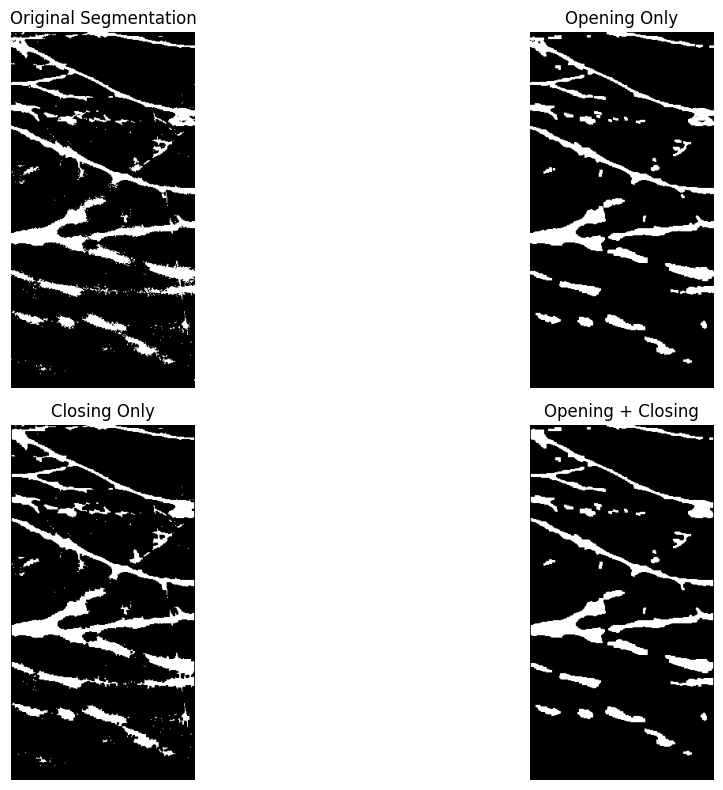

Original pixels: 14653
Opening pixels: 12879
Closing pixels: 15534
Opening + Closing pixels: 12885


In [27]:

# STEP 11.3: Combined Morphological Processing

images = [
    ("Original Segmentation", binary),
    ("Opening Only", opened),
    ("Closing Only", closed),
    ("Opening + Closing", final_result)
]

plt.figure(figsize=(14, 8))

for i, (title, img) in enumerate(images):
    plt.subplot(2, 2, i + 1)
    plt.imshow(img, cmap="gray", vmin=0, vmax=255)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Count pixels in the combined result
final_count = sum(
    1 for row in final_result
    for pixel in row if pixel == 255
)

print("Original pixels:", before_count)
print("Opening pixels:", opening_count)
print("Closing pixels:", closing_count)
print("Opening + Closing pixels:", final_count)



### Additional Experiment: Opening Followed by Closing

An additional experiment was conducted by applying closing to the opening result, using the same 3×3 structuring element.

The original segmentation contained 14,653 foreground pixels. After opening, the number decreased to 12,879 pixels. Applying closing afterward resulted in 12,885 foreground pixels.

The combined operation therefore produced a net increase of only 6 foreground pixels compared to opening alone.

Visually, the results of opening and opening followed by closing were almost identical. This indicates that closing introduced only minor changes after opening in this experiment.

Opening alone was considered more suitable for removing small foreground noise because it produced a cleaner result with fewer processing steps.

However, some thin tree shadows were also removed. Therefore, the result should not be considered perfectly accurate.



## Conclusion

In this assignment, thresholding-based image segmentation and four basic morphological operations were successfully implemented manually without using built-in image processing functions.

The segmentation was performed using a threshold value of 150 to separate dark tree shadows from the brighter building wall.

The results showed that:

1. **Erosion** reduced foreground regions and removed small details, but also caused some thin branches to disappear.
2. **Dilation** expanded the detected shadow regions and connected nearby foreground pixels, but also enlarged unwanted regions.
3. **Opening** removed small foreground noise while preserving many larger shadow structures.
4. **Closing** filled some small gaps while maintaining most of the original foreground structure.

An additional experiment combining opening and closing produced a result very similar to opening alone.

Overall, opening was the preferred morphological operation for reducing small foreground noise in this image. However, the experiment also demonstrated that morphological processing can remove useful details.

The quality of the final segmentation depends on the threshold value, image characteristics, and structuring element. Since no ground-truth segmentation mask was available, the evaluation was based on visual comparison and foreground pixel counts rather than segmentation accuracy.
